# OCR et image captioning

Un sujet commun : produire un texte à partir d’une image. L’OCR transcrit les caractères présents ; le captioning décrit la scène. Leurs références et leurs métriques diffèrent.

Ce notebook réunit les deux démonstrations, dans l’ordre : transcription avec CER/WER, puis légendes avec BLEU/ROUGE-L. Les légendes candidates sont construites à la main pour isoler les propriétés des métriques. Exécuter les cellules dans l’ordre.


# OCR : évaluer la transcription

**Objectif :** calculer CER, WER et exactitude sur une vraie sortie de Tesseract. Corpus contrôlé de trois images imprimées, créé pour expliquer les erreurs ; ce n’est pas un benchmark représentatif. Exécuter les cellules dans l’ordre. CPU suffisant.

Dans Colab : importer le ZIP du projet dans le panneau Fichiers, le décompresser, puis `%cd` vers `projet_evaluation_cv`. L’installation ci-dessous est nécessaire uniquement si les dépendances manquent.


In [1]:
# Dans Colab, décommenter si nécessaire :
# !pip -q install -r requirements.txt
# !apt-get -qq update && apt-get -qq install -y tesseract-ocr


In [2]:
from pathlib import Path
import sys
# Fonctionne depuis la racine du dépôt ou depuis notebooks/.
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
assert (ROOT/"src").exists(), "Ouvrir le notebook dans le dépôt extrait"
sys.path.insert(0, str(ROOT))
(ROOT/"results").mkdir(exist_ok=True)
import json
import matplotlib.pyplot as plt
import pandas as pd


## 1. Créer des images dont on connaît le texte
La vérité terrain est écrite avant la reconnaissance. Les images incluent une ligne nette, une ligne peu lisible et une référence proche visuellement de chiffres. Le français des explications est conservé ; le moteur `eng` suffit ici car les trois lignes ne contiennent aucun accent.


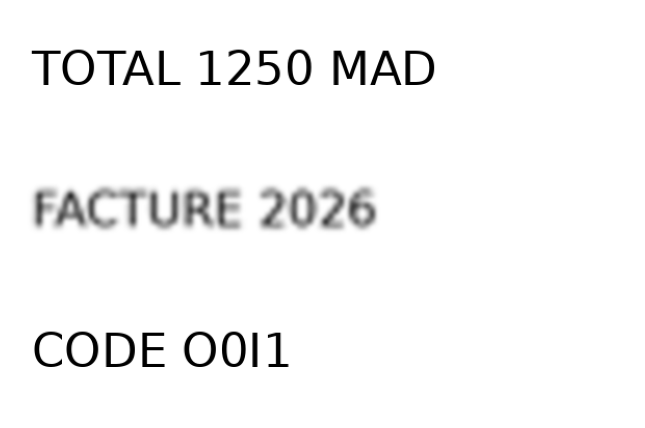

In [3]:
from PIL import Image, ImageDraw, ImageFont, ImageFilter
import shutil, subprocess, tempfile
refs = ["TOTAL 1250 MAD", "FACTURE 2026", "CODE O0I1"]
font_path = "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"
if not Path(font_path).exists():
    # Alternative Windows : définir ici C:/Windows/Fonts/arial.ttf
    raise FileNotFoundError("Adapter font_path à une police TrueType installée")
font = ImageFont.truetype(font_path, 45)
images = []
for i, ref in enumerate(refs):
    image = Image.new("RGB", (600, 120), "white")
    ImageDraw.Draw(image).text((20,30), ref, font=font, fill="black")
    if i == 1:
        image = image.resize((120,24)).resize((600,120)).filter(ImageFilter.GaussianBlur(1.4))
    images.append(image)
    image.save(ROOT/f"data/ocr_{i}.png")
fig, axes = plt.subplots(3,1,figsize=(10,4))
for ax, image in zip(axes,images):
    ax.imshow(image); ax.axis("off")
plt.tight_layout(); plt.savefig(ROOT/"results/ocr_images.png",dpi=140); plt.show()


## 2. Reconnaître puis normaliser de manière identique
`--psm 7` indique une ligne de texte. On réduit les espaces consécutifs et on ignore la casse des deux côtés. La ponctuation et les confusions O/0 restent des erreurs. Le moteur n’est pas entraîné ici.


In [4]:
if not shutil.which("tesseract"):
    raise RuntimeError("Installer Tesseract puis relancer cette cellule")
preds = []
for i in range(len(images)):
    output = subprocess.run(["tesseract",str(ROOT/f"data/ocr_{i}.png"),"stdout",
                             "-l","eng","--psm","7"],capture_output=True,text=True,check=True)
    preds.append(" ".join(output.stdout.upper().split()))
refs = [" ".join(r.upper().split()) for r in refs]
print(pd.DataFrame({"Référence":refs,"Prédiction OCR":preds}).to_string(index=False))


     Référence Prédiction OCR
TOTAL 1250 MAD TOTAL 1250 MAD
  FACTURE 2026   FACTURE 2026
     CODE O0I1      CODE OOI1


## 3. Calculer CER et WER
Pour chaque niveau, taux = (substitutions + suppressions + insertions) / nombre d’unités de référence. Le CER inclut les espaces. Le WER utilise les mots séparés par des espaces. On additionne les éditions avant de diviser : ce n’est pas la moyenne des taux par ligne.


In [5]:
from src.metrics import distance, error_rates
scores = error_rates(refs,preds)
print(pd.Series(scores).map(lambda x:f"{x:.2%}"))
(ROOT/"results/ocr_scores.json").write_text(json.dumps(scores,indent=2))
# Exemple vérifiable à la main : une substitution parmi 4 caractères.
assert distance("CHAT","CH4T") == 1
print("CHAT → CH4T : CER =", distance("CHAT","CH4T")/4,
      "; WER =", distance(["CHAT"],["CH4T"])/1)
# Des insertions peuvent rendre le taux supérieur à 100 %.
assert error_rates(["A"],["AAAA"])["CER"] == 3


CER            2.86%
WER           14.29%
Exactitude    66.67%
dtype: object
CHAT → CH4T : CER = 0.25 ; WER = 1.0


## 4. Lire les erreurs
CER et WER : plus petits = meilleurs ; exactitude : plus grande = meilleure. Une seule faute peut invalider un montant même avec un CER faible. Trois lignes ne permettent pas de conclure à la qualité générale du moteur. La détection des zones de texte nécessiterait aussi IoU et précision/rappel, hors de cette démonstration de transcription.


In [6]:
rows=[]
for ref,pred in zip(refs,preds):
    rows.append({"Référence":ref,"OCR":pred,**error_rates([ref],[pred])})
table=pd.DataFrame(rows)
print(table.to_string(index=False))
table.to_csv(ROOT/"results/ocr_details.csv",index=False)


     Référence            OCR      CER  WER  Exactitude
TOTAL 1250 MAD TOTAL 1250 MAD 0.000000  0.0         1.0
  FACTURE 2026   FACTURE 2026 0.000000  0.0         1.0
     CODE O0I1      CODE OOI1 0.111111  0.5         0.0


## Sources et exercice
- CER : https://github.com/huggingface/evaluate/blob/main/metrics/cer/cer.py
- Tesseract : https://tesseract-ocr.github.io/tessdoc/Command-Line-Usage.html

**À expliquer :** pourquoi `CHAT → CH4T` donne-t-il 25 % de CER mais 100 % de WER ? Réponse : un caractère sur quatre est erroné, mais l’unique mot est incorrect. Changer la dégradation d’une image et observer les sorties, sans supposer que le flou augmente toujours les erreurs.


# Image captioning : évaluer des légendes

**Objectif :** comprendre BLEU-1, BLEU-4 et ROUGE-L avec deux vraies images et plusieurs références françaises par image. Les légendes candidates sont **construites à la main**, pas produites par un modèle. C’est une démonstration contrôlée des métriques demandées, pas une mesure de performance d’un générateur. Aucun modèle lourd à télécharger.


In [7]:
# Dans Colab si nécessaire :
# !pip -q install -r requirements.txt


In [8]:
from pathlib import Path
import sys
# Fonctionne depuis la racine du dépôt ou depuis notebooks/.
ROOT = Path.cwd() if (Path.cwd()/"src").exists() else Path.cwd().parent
assert (ROOT/"src").exists(), "Ouvrir le notebook dans le dépôt extrait"
sys.path.insert(0, str(ROOT))
(ROOT/"results").mkdir(exist_ok=True)
import json
import matplotlib.pyplot as plt
import pandas as pd


## 1. Afficher les images et les références
Les images `china.jpg` et `flower.jpg` sont incluses dans scikit-learn. Deux descriptions manuelles par image montrent qu’une image peut avoir plusieurs légendes acceptables.


{
  "références": [
    [
      "un bâtiment traditionnel près des arbres",
      "un édifice avec un jardin et des arbres"
    ],
    [
      "une fleur orange devant un fond vert",
      "une fleur aux pétales orange dans la nature"
    ]
  ],
  "candidats": {
    "Proches des références": [
      "un bâtiment traditionnel près des arbres",
      "une fleur orange devant un fond vert"
    ],
    "Paraphrases": [
      "une construction asiatique dans un jardin",
      "des pétales orangés entourés de verdure"
    ],
    "Erreurs de sens": [
      "un bâtiment traditionnel près des voitures",
      "une fleur bleue devant un fond vert"
    ]
  }
}


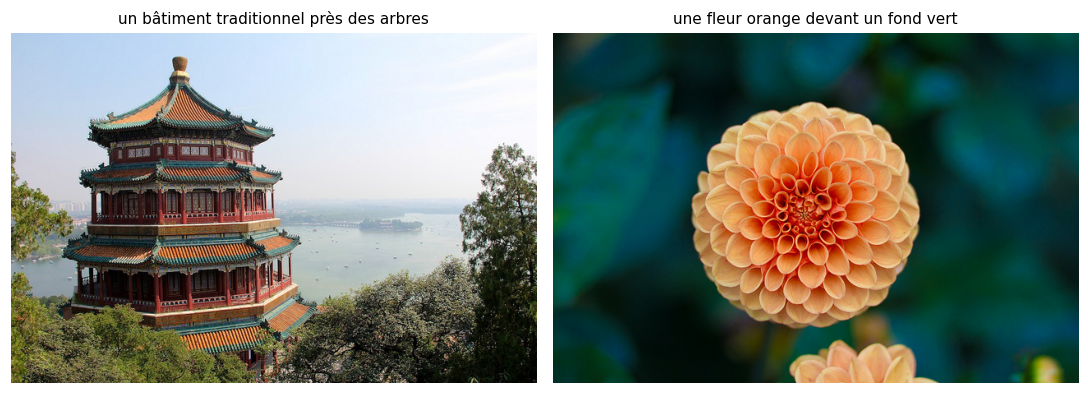

In [9]:
from sklearn.datasets import load_sample_images
from PIL import Image
sample=load_sample_images()
images=sample.images
references=[
 ["un bâtiment traditionnel près des arbres", "un édifice avec un jardin et des arbres"],
 ["une fleur orange devant un fond vert", "une fleur aux pétales orange dans la nature"]]
candidates={
 "Proches des références":["un bâtiment traditionnel près des arbres","une fleur orange devant un fond vert"],
 "Paraphrases":["une construction asiatique dans un jardin","des pétales orangés entourés de verdure"],
 "Erreurs de sens":["un bâtiment traditionnel près des voitures","une fleur bleue devant un fond vert"]}
fig,axes=plt.subplots(1,2,figsize=(10,4))
for i,(ax,image,refs) in enumerate(zip(axes,images,references)):
    ax.imshow(image);ax.axis("off");ax.set_title(refs[0],fontsize=10)
    Image.fromarray(image).save(ROOT/f"data/caption_{i}.jpg")
plt.tight_layout();plt.savefig(ROOT/"results/caption_images.png",dpi=140);plt.show()
print(json.dumps({"références":references,"candidats":candidates},ensure_ascii=False,indent=2))


## 2. BLEU et ROUGE-L
BLEU-N combine les précisions écrêtées des groupes de 1 à N mots avec une pénalité si le candidat est trop court. On calcule BLEU sur le corpus, sans lissage. BLEU-4 peut être nul si aucun groupe de quatre mots ne correspond. ROUGE-L mesure une sous-séquence commune dans le bon ordre ; ici F1, sans racinisation, maximum sur les références, puis moyenne sur les images. Mêmes tokens pour tous : minuscules, ponctuation supprimée, accents conservés.


In [10]:
from src.metrics import bleu_corpus,rouge_l
rows=[]
for name,preds in candidates.items():
    rows.append({"Candidats":name,"BLEU-1":bleu_corpus(references,preds,n=1),
                 "BLEU-4":bleu_corpus(references,preds,n=4),
                 "ROUGE-L F1":sum(max(rouge_l(r,p) for r in refs)
                                     for refs,p in zip(references,preds))/len(preds)})
table=pd.DataFrame(rows).set_index("Candidats")
print(table.round(3).to_string())
table.to_csv(ROOT/"results/caption_scores.csv")
assert abs(table.iloc[0]["BLEU-4"]-1)<1e-12
assert rouge_l("un chat noir","un chat noir")==1
assert bleu_corpus([["un chat noir"]],["un chien blanc"],n=4)==0


                        BLEU-1  BLEU-4  ROUGE-L F1
Candidats                                         
Proches des références   1.000   1.000       1.000
Paraphrases              0.230   0.000       0.214
Erreurs de sens          0.846   0.619       0.845


## 3. Comparer les scores au sens de l’image
Plus le score est élevé, plus les mots correspondent aux références. Cela ne garantit pas la fidélité visuelle : remplacer « orange » par « bleue » laisse presque toute la phrase inchangée. Une paraphrase correcte peut recevoir un score plus faible. Ces deux images sont insuffisantes pour classer des systèmes.


Image 1 | référence : un bâtiment traditionnel près des arbres
Erreur contrôlée : un bâtiment traditionnel près des voitures
Image 2 | référence : une fleur orange devant un fond vert
Erreur contrôlée : une fleur bleue devant un fond vert


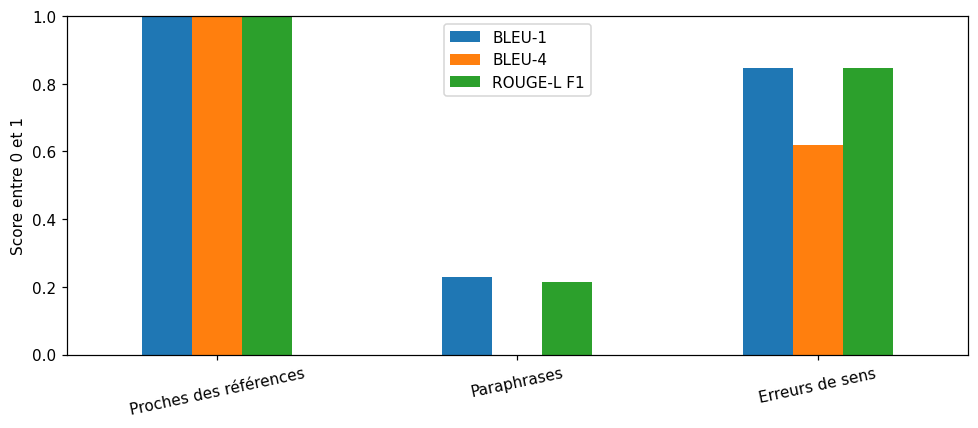

In [11]:
ax=table.plot.bar(figsize=(9,4),ylim=(0,1),rot=12)
ax.set_ylabel("Score entre 0 et 1");ax.set_xlabel("")
plt.tight_layout();plt.savefig(ROOT/"results/caption_scores.png",dpi=150);plt.show()
for i,refs in enumerate(references):
    print("Image",i+1,"| référence :",refs[0])
    print("Erreur contrôlée :",candidates["Erreurs de sens"][i])


## 4. Élargir l’évaluation
**CIDEr** compare des n-grammes pondérés TF-IDF avec le consensus de plusieurs références. Son calcul requiert un corpus suffisamment riche pour des pondérations pertinentes. **METEOR** prend en compte des alignements plus souples, selon ses ressources linguistiques. **CLIPScore** compare image et texte dans un espace multimodal, sans référence, avec ses propres biais. Ces trois métriques sont présentées comme prolongements, pas calculées ici. Pour une vraie étude : beaucoup d’images inédites, références indépendantes, mêmes conventions pour tous les modèles, et jugement humain de fidélité et de fluidité.

## Sources
- BLEU : https://aclanthology.org/P02-1040/
- ROUGE : https://aclanthology.org/W04-1013/
- CIDEr : https://openaccess.thecvf.com/content_cvpr_2015/html/Vedantam_CIDEr_Consensus-Based_Image_2015_CVPR_paper.html
- Évaluation humaine : https://aclanthology.org/2022.naacl-main.254/

**À expliquer :** pourquoi une légende visuellement fausse peut-elle garder un bon score lexical ?
